<a href="https://colab.research.google.com/github/Paul-Daly366/MachineLearning_Project_Colab/blob/main/MachineLearningProj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Machine Learning Project - Campus Insights**

## **Project Details**

### **Student Info**
Paul Daly, G00470372


### **Project Info**
How can data collected during a campus nature walk
be used to investigate the relationship between
environmental characteristics and human
experience?

This is a Research and Development Project aimed at spotting and investigating relationships between data, using various tools to prepare & visualise data, as well as generate predicted data by training Machine Learning algorithms.

## **Imports and Config**

### **Imports**

In [169]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Loading Dataset**

In [170]:
df = pd.read_csv('/content/drive/MyDrive/Data/MLProject - Campus Data.csv',skiprows=4)

## **Inspecting & Cleaning up the Dataset**

### **Inspecting with pandas library**

In [171]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    object 
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 132 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature                133 non-null    object 
 11  insect

### **Cleaning up**

*Basic removal of empty cells from the DataFrame.*

In [172]:
df = df.dropna(axis=0, how='all')
df = df.dropna(axis=1, how='all')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199 entries, 0 to 198
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    object 
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 132 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature                133 non-null    object 
 11  insects_cou

## **Investigating Data**
*Inspecting the data and apparent relationships between data in the DataFrame.*

### **Weather v Temperature**

*This section is a display of my attempt to showing a correlation between weather and recorded temperature. This is mostly a demonstration of the Python and pandas functions in relation to dataframes.*

*In this section:*
*   *Creating an initial DataFrame to use*
*   *Cleaning and preparing the data for use with plots and algorithms*
*   *A plot of the relationship between Weather and Temperature*
*   *A line of best fit created by the Linear Regression ML Algorithm*






#### **WvT: Cleaning & Preparing the Data within the Data Frame**

*Creating a seperate DataFrame, dropping empty cells, and adjust the data into lowercase strings.*

In [173]:
df_weather_temp = df[["weather","temperature_c"]]
df_weather_temp = df_weather_temp.dropna()
df_weather_temp_initial = df_weather_temp

df_weather_temp['weather'] = df_weather_temp['weather'].str.strip().str.lower()
df_weather_temp['temperature_c'] = df_weather_temp['temperature_c'].str.strip().str.lower()



In [174]:
# INITIAL DATAFRAME FOR WvT
df_weather_temp_initial.sample(5)

,weather,temperature_c
64,sunny,18
36,partly cloudy,16
105,sunny,17
57,cloudy,13
103,sunny,17


#### **WvT: Encoding Weather Categories**

*Weather is entered as strings in the table, we need to encode it to plot it or use it in ML algorithms.*

*First a dictionary is made for mapping values to the weather categories, then a new column is created from the mapped weather column, we inspect weather compared to weather_encoded, then the previous weather column is dropped.*

In [175]:
weather_mapping = {
    'windy':0,
    'cloudy':1,
    'partly cloudy':2,
    'sunny':3
}

df_weather_temp['weather_encoded'] = df_weather_temp['weather'].map(weather_mapping)

# Test DataFrame for comparing in the following code cell, this allows the comparison cell to be run again and again
df_weather_encoded = df_weather_temp

# Dropping the old weather column by reinitializing the DataFrame
df_weather_temp = df_weather_temp[["weather_encoded","temperature_c"]]

In [176]:
# WEATHER COMPARISON
# Showing a sample of the dataframe to compare the old and new weather columns
df_weather_encoded.sample(5)

,weather,temperature_c,weather_encoded
20,sunny,16,3
74,sunny,17,3
41,sunny,16,3
7,sunny,19,3
69,sunny,18,3


In [177]:
# Checking weather categories vs applied labels
for x in range(10):
  print(f"Weather: {df_weather_encoded['weather'].loc[df_weather_encoded.index[x]]},"f" Encoded as: {df_weather_encoded['weather_encoded'].loc[df_weather_encoded.index[x]]}")

Weather: partly cloudy, Encoded as: 2
Weather: sunny, Encoded as: 3
Weather: partly cloudy, Encoded as: 2
Weather: partly cloudy, Encoded as: 2
Weather: sunny, Encoded as: 3
Weather: sunny, Encoded as: 3
Weather: windy, Encoded as: 0
Weather: sunny, Encoded as: 3
Weather: cloudy, Encoded as: 1
Weather: sunny, Encoded as: 3


#### **WvT: Fixing temperature values**

*Temperature data may have been entered as a string containing a c character, to fix this, the we can replace c with an empty character, and then convert that string into a float, to isolate the number value.*

In [178]:
df_weather_temp['temperature_c_fixed'] = df_weather_temp['temperature_c'].str.replace('c','')
df_weather_temp['temperature_c_fixed'] = df_weather_temp['temperature_c_fixed'].astype(float)

# Test DataFrame for comparing in the following code cell, this allows the comparison cell to be run again and again
df_temp_fix = df_weather_temp

In [179]:
# TEMPERAURE COMPARISON
# Showing a sample of the dataframe to compare the old and new temperature columns
df_temp_fix.sample(5)

,weather_encoded,temperature_c,temperature_c_fixed
25,2,16,16.0
7,3,19,19.0
86,2,16,16.0
59,3,16,16.0
101,3,17,17.0


In [180]:
# Reinitialize the DataFrame, removing the old temperature_c column
df_weather_temp = df_weather_temp[["weather_encoded","temperature_c_fixed"]]

In [181]:
# Inspecting the frequency of temperature values in temperature_c_fixed
# This would also show any invalid values
if 'temperature_c_fixed' in df_weather_temp.columns:
  print(df_weather_temp['temperature_c_fixed'].value_counts(dropna=False))
else:
  print('Error')

temperature_c_fixed
17.0    72
16.0    35
18.0    12
19.0     6
15.0     4
10.0     3
13.0     1
16.5     1
14.0     1
Name: count, dtype: int64


#### **WvT: Plot**

*Using pandas library to make a plot graph, we create a plot object with the .plot.scatter() function, providing several parameters to configure it, including a title and axis labels.*

In [182]:
df_weather_temp.sample(5)

,weather_encoded,temperature_c_fixed
1,3,16.0
26,2,16.0
73,3,17.0
45,2,17.0
102,3,17.0


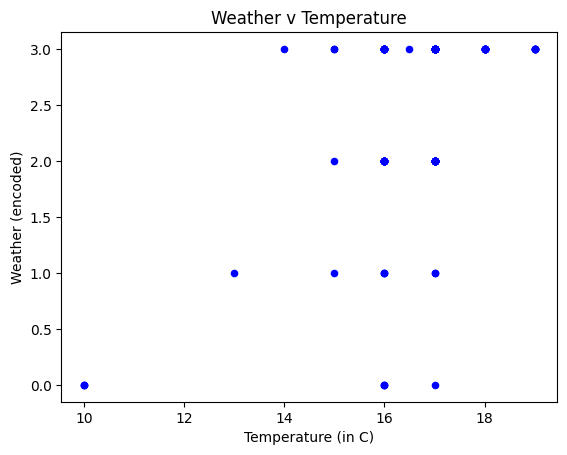

In [183]:
#print(df_weather_temp_encoded.head)
WvT_Plot = df_weather_temp.plot.scatter(y=['weather_encoded'],x=['temperature_c_fixed'],
xlabel="Temperature (in C)", ylabel="Weather (encoded)", title="Weather v Temperature", c="Blue")


#### **WvT: Linear Regression**

*Create training & testing data for the model, train the model with the training data, visualise this model by creating a line of best fit, and test the model with test data.*

*We create training and testing data by first assigning x y variables, then running a sklearn function to split the data into training and testing data, in our case 75% is for training and 25% for testing.*

*The random_state parameter shuffles the data to avoid any accidental correlation*

In [184]:
x = df_weather_temp['temperature_c_fixed']
x = np.array(x)
x = x.reshape(-1,1)

y = df_weather_temp['weather_encoded']
y = np.array(y)
y = y.reshape(-1,1)

In [185]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.25,
    random_state = 12
)

# Printing the length of the data
print(f"Training observations: {len(x_train)}")
print(f"Test observations: {len(x_test)}")

Training observations: 101
Test observations: 34


In [186]:
w_t_model = LinearRegression()

w_t_model.fit(x_train,y_train)

LinearRegression()

#### **WvT: Inspecting Model**

In [188]:
# TODO: Print values related to equation & show actual equation, plus contextualise
beta_0 = w_t_model.intercept_
beta_1 = w_t_model.coef_[0]

## Decision Logs

### Week 1 - 8/10/26

| Item | Details |
|-------|---------|
| Issue or Challenge Identified | Irrelevant/Empty rows & columns in Data Frame |
| Decision Taken | Remove the rows & columns with pandas functions, learnt df.dropna() |
| Justification | Effective & non-obstructing code |
| Evidence Supporting the Decision | Checked Data Frame before using functions, checked pandas documentation |
| Reflection | Learnt how pandas functions & parameters work, learnt how to navigate & read pandas docs |

### Week 2 - 15/10/26

| Item | Details |
|-------|---------|
| Issue or Challenge Identified | Figuring out how to isolate and prepare specific columns |
| Decision Taken | Check documentation and guides, use functions like Label Enconding and String replacing |
| Justification | Weather categories need a numerical value to plot, and temperature values in data were incorrectly inputted |
| Evidence Supporting the Decision | Printing the corrected dataframe shows data we can work with in plots |
| Reflection | Learnt a lot about the functionality of pandas dataframes and python libraries |

### Week 3 - 22/10/26

| Item | Details |
|-------|---------|
| Issue or Challenge Identified | Messy inconsistent layout and code flow, hard to understand or follow |
| Decision Taken | Restructure & rewrite some code, made checkpoint DataFrames for point inspecting |
| Justification | Several code cells can now be run without failure or impacting other cells, to see what the nearby code is doing |
| Evidence Supporting the Decision | Tested and got a colleague to try following code flow |
| Reflection | Learned better functions and code layout, will be less confusing to work on this project in the future |